# RQ5 — Age × Diagnosis Interactions in Cortical Thickness
### Do ASD and control brains follow *different developmental trajectories*?

**Research question (RQ5):** *Are cortical-thinning trajectories with age different for ASD vs. controls? We fit linear mixed-effects models with an age x diagnosis interaction and site as a random effect.*

**Why this matters.** RQ1 compared group *means* (controlling for age) and found only tiny, near-chance differences; RQ4 classification plateaued at ~0.55 AUC. Both are *static* (single-snapshot) views. But cortical thickness changes with age, and autism may differ in the *rate of change* rather than the average level. Two runners can finish in the same place yet take different paths — a snapshot at the finish line hides the divergence. RQ5 tests the path.

---
## Methodology

**Primary model (per region, 68 total):**
```
thickness ~ C(DX_GROUP) * age + C(SEX) + (1 | SITE_ID)
```
a linear mixed-effects model with a random intercept for site (matching the robust RQ1 'Model B2' approach). The term of interest is the **C(DX_GROUP):age interaction** — a significant value means the two groups have different age-slopes. Age is mean-centred for stability. DX_GROUP is coded 1=ASD (reference), 2=Control, so:
- ASD age-slope = coefficient of `age`
- Control age-slope = `age` + interaction coefficient

**Two age ranges, compared (robustness):**
1. **Full range (6.5-64 yrs)** — maximum age leverage.
2. **Developmental window (<=30 yrs)** — the period of most active cortical change, excludes the sparse older tail (only ~7% of subjects are >30) which can distort a linear slope.

**Multiple comparisons:** Benjamini-Hochberg FDR across the 68 regions (q<0.05).

**Independent robustness check:** the same interaction is re-tested with OLS on the ComBat-harmonised data (where site variance is already removed), to confirm findings do not depend on the random-effect fitting.

**Data:** uncorrected merged data (`abide_merged.csv`); site handled directly via the random effect.

### Imports & configuration

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')   # MixedLM boundary warnings on near-zero site variance; fixed-effect inference unaffected
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess

RANDOM_STATE = 42
AGE_CUTOFF   = 30
sns.set_style('whitegrid')
print('Imports OK')

Imports OK


---
## Block 1 — Load data, inspect age distribution, prepare

Subjects: 1027  | ASD=499  Control=528  Sites=20
Age: 6.5-64.0  median=14.6  >30: 77 (7%)


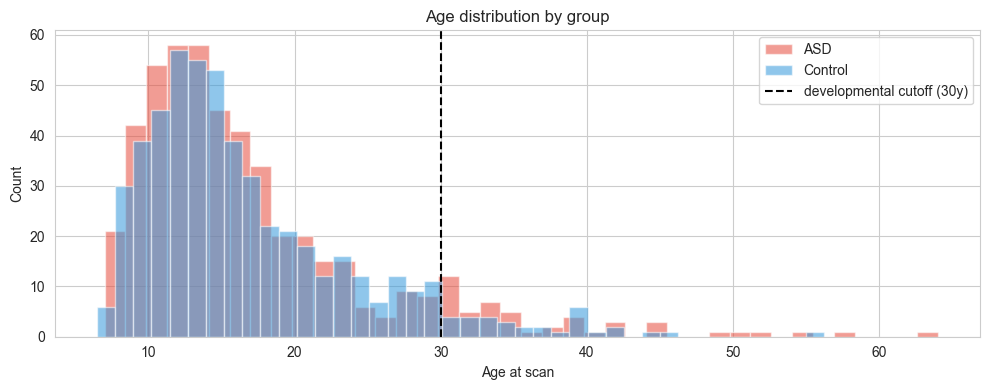

In [4]:
df = pd.read_csv('abide_merged.csv')
df.replace(-9999, np.nan, inplace=True)
THICKNESS_COLS = [c for c in df.columns if c.startswith(('lh_', 'rh_'))]
df = df.dropna(subset=THICKNESS_COLS + ['AGE_AT_SCAN', 'SEX', 'DX_GROUP']).reset_index(drop=True)
df['DX_LABEL'] = df['DX_GROUP'].map({1: 'ASD', 2: 'Control'})

print(f'Subjects: {len(df)}  | ASD={int((df.DX_GROUP==1).sum())}  Control={int((df.DX_GROUP==2).sum())}  Sites={df.SITE_ID.nunique()}')
print(f'Age: {df.AGE_AT_SCAN.min():.1f}-{df.AGE_AT_SCAN.max():.1f}  median={df.AGE_AT_SCAN.median():.1f}  '
      f'>30: {int((df.AGE_AT_SCAN>30).sum())} ({(df.AGE_AT_SCAN>30).mean()*100:.0f}%)')

fig, ax = plt.subplots(figsize=(10, 4))
for g, c in [('ASD', '#e74c3c'), ('Control', '#3498db')]:
    ax.hist(df[df.DX_LABEL==g]['AGE_AT_SCAN'], bins=40, alpha=0.55, label=g, color=c)
ax.axvline(AGE_CUTOFF, ls='--', color='black', lw=1.5, label=f'developmental cutoff ({AGE_CUTOFF}y)')
ax.set_xlabel('Age at scan'); ax.set_ylabel('Count'); ax.set_title('Age distribution by group'); ax.legend()
plt.tight_layout(); plt.savefig('rq5_age_distribution.png', dpi=130, bbox_inches='tight'); plt.show()

---
## Block 2 — Fit the age x diagnosis interaction across all 68 regions

We define one helper that fits the mixed model per region, extracts the interaction term, both group slopes, and the convergence flag, then applies FDR correction.

In [5]:
def run_interaction(data, label):
    d = data.copy()
    d['age_c'] = d['AGE_AT_SCAN'] - d['AGE_AT_SCAN'].mean()
    rows = []
    for col in THICKNESS_COLS:
        tmp = d[['DX_GROUP', 'age_c', 'SEX', 'SITE_ID']].copy()
        tmp['y'] = d[col].values
        try:
            r = smf.mixedlm('y ~ C(DX_GROUP)*age_c + C(SEX)', tmp,
                            groups=tmp['SITE_ID']).fit(reml=True, method='lbfgs')
            it = [p for p in r.params.index if ':age_c' in p][0]
            rows.append(dict(region=col, beta_interaction=r.params[it], p=r.pvalues[it],
                             asd_slope=r.params['age_c'],
                             ctrl_slope=r.params['age_c'] + r.params[it],
                             converged=r.converged))
        except Exception:
            rows.append(dict(region=col, beta_interaction=np.nan, p=np.nan,
                             asd_slope=np.nan, ctrl_slope=np.nan, converged=False))
    res = pd.DataFrame(rows)
    res['p_fdr'] = multipletests(res['p'], method='fdr_bh')[1]
    res['sig_fdr'] = res['p_fdr'] < 0.05
    res['slope_diff'] = res['asd_slope'] - res['ctrl_slope']   # >0 => ASD thins more slowly
    print(f'[{label}] N={len(d)} | converged {int(res.converged.sum())}/68 | '
          f'raw p<.05: {int((res.p<0.05).sum())}/68 | FDR q<.05: {int(res.sig_fdr.sum())}/68')
    return res.sort_values('p').reset_index(drop=True)

results_full = run_interaction(df, 'FULL 6.5-64')
print('\nTop 10 regions (full range), ASD vs Control age-slopes:')
show = results_full.head(10)[['region','beta_interaction','p','p_fdr','asd_slope','ctrl_slope']]
print(show.to_string(index=False))

[FULL 6.5-64] N=1027 | converged 68/68 | raw p<.05: 25/68 | FDR q<.05: 10/68

Top 10 regions (full range), ASD vs Control age-slopes:
                 region  beta_interaction        p    p_fdr  asd_slope  ctrl_slope
     rh_superiorfrontal         -0.006348 0.000134 0.009117  -0.015201   -0.021550
     lh_superiorfrontal         -0.005623 0.000668 0.020268  -0.015639   -0.021262
 rh_caudalmiddlefrontal         -0.005341 0.000894 0.020268  -0.012451   -0.017792
  lh_transversetemporal         -0.006029 0.002264 0.025773  -0.012656   -0.018685
rh_rostralmiddlefrontal         -0.004652 0.002456 0.025773  -0.016118   -0.020770
           lh_precuneus         -0.004071 0.002459 0.025773  -0.017445   -0.021516
          lh_entorhinal         -0.010014 0.002653 0.025773   0.001039   -0.008975
    rh_superiorparietal         -0.003705 0.003550 0.027028  -0.014697   -0.018402
    rh_inferiorparietal         -0.004202 0.003577 0.027028  -0.016160   -0.020363
             lh_lingual         -0.0

---
## Block 3 — Repeat in the developmental window (<=30 years)

In [6]:
results_rest = run_interaction(df[df.AGE_AT_SCAN <= AGE_CUTOFF], f'RESTRICTED <={AGE_CUTOFF}')
print('\nTop 10 regions (restricted range):')
print(results_rest.head(10)[['region','beta_interaction','p','p_fdr','asd_slope','ctrl_slope']].to_string(index=False))

[RESTRICTED <=30] N=950 | converged 68/68 | raw p<.05: 9/68 | FDR q<.05: 0/68

Top 10 regions (restricted range):
                 region  beta_interaction        p    p_fdr  asd_slope  ctrl_slope
          lh_entorhinal         -0.017040 0.001214 0.082538   0.006473   -0.010568
     rh_superiorfrontal         -0.007354 0.005042 0.093832  -0.020527   -0.027881
     lh_superiorfrontal         -0.007289 0.005298 0.093832  -0.020436   -0.027725
 rh_caudalmiddlefrontal         -0.007005 0.005520 0.093832  -0.017118   -0.024123
       lh_supramarginal         -0.006028 0.010243 0.139302  -0.018471   -0.024499
 lh_caudalmiddlefrontal         -0.005632 0.029668 0.336237  -0.017043   -0.022675
rh_rostralmiddlefrontal         -0.004762 0.043968 0.346052  -0.024625   -0.029387
    lh_inferiortemporal         -0.006128 0.049117 0.346052  -0.017108   -0.023237
     lh_parsopercularis         -0.004683 0.049791 0.346052  -0.013964   -0.018646
            rh_fusiform         -0.005002 0.050890 0.346

---
## Block 4 — Compare the two ranges

Do the same regions emerge? Are the interaction effects consistent in direction and magnitude?

FDR-significant in BOTH ranges : 0  []
Significant only in FULL range : 10  ['lh_entorhinal', 'lh_lingual', 'lh_precuneus', 'lh_superiorfrontal', 'lh_transversetemporal', 'rh_caudalmiddlefrontal', 'rh_inferiorparietal', 'rh_rostralmiddlefrontal', 'rh_superiorfrontal', 'rh_superiorparietal']
Significant only in RESTRICTED : 0  []


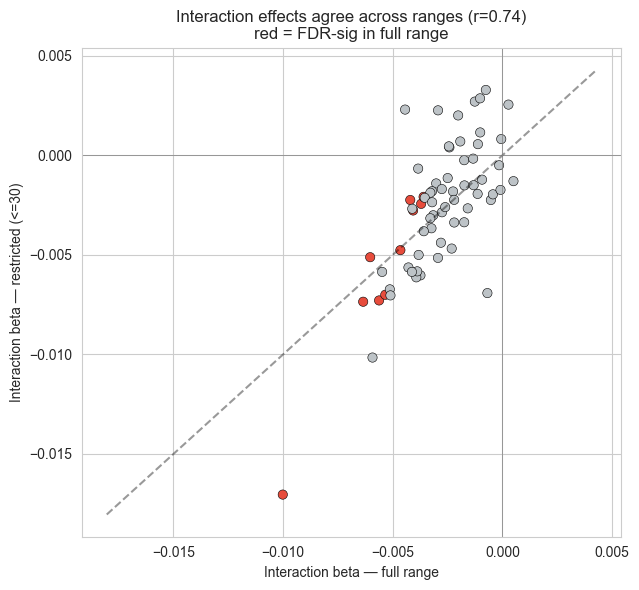


Correlation of interaction betas (full vs restricted): r = 0.738
Interpretation: same direction/magnitude across ranges; the restricted window simply has less
age leverage + smaller N, so fewer regions survive FDR despite consistent effects.


In [7]:
merged = results_full[['region','beta_interaction','p_fdr','sig_fdr']].merge(
    results_rest[['region','beta_interaction','p_fdr','sig_fdr']],
    on='region', suffixes=('_full','_rest'))

both = sorted(set(results_full[results_full.sig_fdr].region) & set(results_rest[results_rest.sig_fdr].region))
only_full = sorted(set(results_full[results_full.sig_fdr].region) - set(results_rest[results_rest.sig_fdr].region))
only_rest = sorted(set(results_rest[results_rest.sig_fdr].region) - set(results_full[results_full.sig_fdr].region))
print(f'FDR-significant in BOTH ranges : {len(both)}  {both}')
print(f'Significant only in FULL range : {len(only_full)}  {only_full}')
print(f'Significant only in RESTRICTED : {len(only_rest)}  {only_rest}')

# correlation of interaction betas across ranges
r = np.corrcoef(merged.beta_interaction_full, merged.beta_interaction_rest)[0,1]
fig, ax = plt.subplots(figsize=(6.5, 6))
colors = ['#e74c3c' if s else '#bdc3c7' for s in merged.sig_fdr_full]
ax.scatter(merged.beta_interaction_full, merged.beta_interaction_rest, c=colors, s=45, edgecolors='k', linewidth=0.4)
lim = [merged[['beta_interaction_full','beta_interaction_rest']].min().min()-0.001,
       merged[['beta_interaction_full','beta_interaction_rest']].max().max()+0.001]
ax.plot(lim, lim, 'k--', alpha=0.4); ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
ax.set_xlabel('Interaction beta — full range'); ax.set_ylabel('Interaction beta — restricted (<=30)')
ax.set_title(f'Interaction effects agree across ranges (r={r:.2f})\nred = FDR-sig in full range')
plt.tight_layout(); plt.savefig('rq5_range_comparison.png', dpi=130, bbox_inches='tight'); plt.show()
print(f'\nCorrelation of interaction betas (full vs restricted): r = {r:.3f}')
print('Interpretation: same direction/magnitude across ranges; the restricted window simply has less')
print('age leverage + smaller N, so fewer regions survive FDR despite consistent effects.')

---
## Block 5 — Visualise the trajectories (the key figure)

For the strongest interaction regions, we plot thickness vs age per group with linear fits (matching the model) and a LOWESS smoother (to show the true, possibly non-linear shape). Diverging lines = different developmental trajectories.

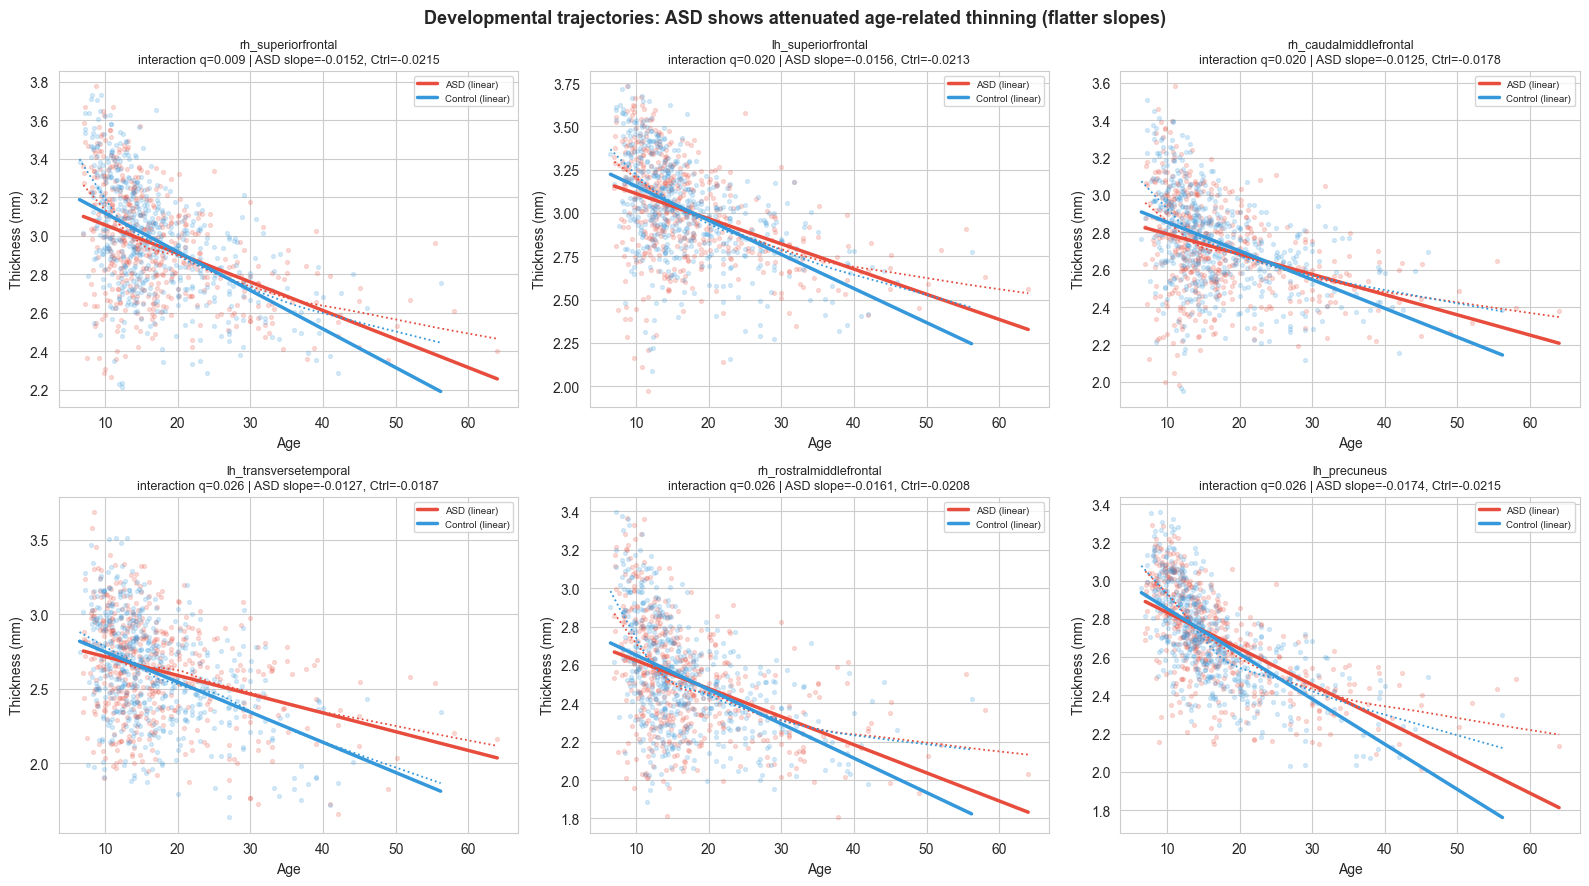

In [8]:
top_regions = results_full.head(6)['region'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
colmap = {'ASD': '#e74c3c', 'Control': '#3498db'}
for ax, reg in zip(axes.ravel(), top_regions):
    for g in ['ASD', 'Control']:
        sub = df[df.DX_LABEL == g]
        ax.scatter(sub.AGE_AT_SCAN, sub[reg], s=8, alpha=0.18, color=colmap[g])
        # linear fit
        xx = np.linspace(sub.AGE_AT_SCAN.min(), sub.AGE_AT_SCAN.max(), 100)
        b = np.polyfit(sub.AGE_AT_SCAN, sub[reg], 1)
        ax.plot(xx, np.polyval(b, xx), color=colmap[g], lw=2.5, label=f'{g} (linear)')
        # lowess
        lo = lowess(sub[reg], sub.AGE_AT_SCAN, frac=0.6)
        ax.plot(lo[:,0], lo[:,1], color=colmap[g], lw=1.3, ls=':')
    row = results_full[results_full.region == reg].iloc[0]
    ax.set_title(f'{reg}\ninteraction q={row.p_fdr:.3f} | ASD slope={row.asd_slope:.4f}, Ctrl={row.ctrl_slope:.4f}',
                 fontsize=9)
    ax.set_xlabel('Age'); ax.set_ylabel('Thickness (mm)'); ax.legend(fontsize=7)
fig.suptitle('Developmental trajectories: ASD shows attenuated age-related thinning (flatter slopes)',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('rq5_trajectories.png', dpi=130, bbox_inches='tight'); plt.show()

---
## Block 6 — Direction of the effect

For every FDR-significant region, is ASD thinning *faster* or *slower* than controls? `slope_diff = ASD_slope - Control_slope`; positive means ASD thins more slowly (attenuated thinning).

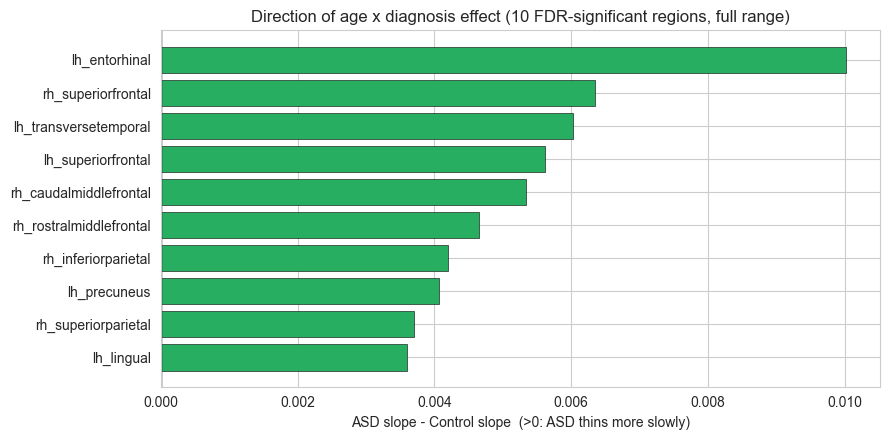

10/10 significant regions show ASD thinning MORE SLOWLY than controls.
Regions (lobe grouping is approximate):
                 region  asd_slope  ctrl_slope  slope_diff    p_fdr
             lh_lingual  -0.012521   -0.016114    0.003593 0.028100
    rh_superiorparietal  -0.014697   -0.018402    0.003705 0.027028
           lh_precuneus  -0.017445   -0.021516    0.004071 0.025773
    rh_inferiorparietal  -0.016160   -0.020363    0.004202 0.027028
rh_rostralmiddlefrontal  -0.016118   -0.020770    0.004652 0.025773
 rh_caudalmiddlefrontal  -0.012451   -0.017792    0.005341 0.020268
     lh_superiorfrontal  -0.015639   -0.021262    0.005623 0.020268
  lh_transversetemporal  -0.012656   -0.018685    0.006029 0.025773
     rh_superiorfrontal  -0.015201   -0.021550    0.006348 0.009117
          lh_entorhinal   0.001039   -0.008975    0.010014 0.025773


In [9]:
sig = results_full[results_full.sig_fdr].sort_values('slope_diff')
fig, ax = plt.subplots(figsize=(9, max(3, 0.45*len(sig))))
colors = ['#27ae60' if v > 0 else '#c0392b' for v in sig.slope_diff]
ax.barh(sig.region, sig.slope_diff, color=colors, edgecolor='k', linewidth=0.4)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('ASD slope - Control slope  (>0: ASD thins more slowly)')
ax.set_title(f'Direction of age x diagnosis effect ({len(sig)} FDR-significant regions, full range)')
plt.tight_layout(); plt.savefig('rq5_direction.png', dpi=130, bbox_inches='tight'); plt.show()

n_asd_slower = int((sig.slope_diff > 0).sum())
print(f'{n_asd_slower}/{len(sig)} significant regions show ASD thinning MORE SLOWLY than controls.')
print('Regions (lobe grouping is approximate):')
print(sig[['region','asd_slope','ctrl_slope','slope_diff','p_fdr']].to_string(index=False))

---
## Block 7 — Independent robustness check (harmonised-data OLS)

Re-test the interaction with OLS on the ComBat-harmonised data. Site variance is already removed there, so no random effect is needed and the convergence warnings of the mixed model do not apply. Agreement confirms the result is real.

In [10]:
dh = pd.read_csv('abide_harmonised_combat.csv'); dh.replace(-9999, np.nan, inplace=True)
dh = dh.dropna(subset=THICKNESS_COLS + ['AGE_AT_SCAN','SEX','DX_GROUP']).reset_index(drop=True)
dh['age_c'] = dh['AGE_AT_SCAN'] - dh['AGE_AT_SCAN'].mean()
rows = []
for col in THICKNESS_COLS:
    tmp = dh[['DX_GROUP','age_c','SEX']].copy(); tmp['y'] = dh[col].values
    r = smf.ols('y ~ C(DX_GROUP)*age_c + C(SEX)', tmp).fit()
    it = [p for p in r.params.index if ':age_c' in p][0]
    rows.append(dict(region=col, p=r.pvalues[it]))
hcheck = pd.DataFrame(rows)
hcheck['p_fdr'] = multipletests(hcheck['p'], method='fdr_bh')[1]
hsig = set(hcheck[hcheck.p_fdr < 0.05].region)
psig = set(results_full[results_full.sig_fdr].region)
print(f'Primary (MixedLM, uncorrected) FDR-sig : {len(psig)} regions')
print(f'Robustness (OLS, harmonised)  FDR-sig  : {len(hsig)} regions')
print(f'Agreement (in both)                    : {len(psig & hsig)} regions')
print(f'  -> {sorted(psig & hsig)}')
agree = len(psig & hsig) / max(len(psig), 1) * 100
print(f'\n{agree:.0f}% of primary findings replicate under the independent method.')

Primary (MixedLM, uncorrected) FDR-sig : 10 regions
Robustness (OLS, harmonised)  FDR-sig  : 10 regions
Agreement (in both)                    : 10 regions
  -> ['lh_entorhinal', 'lh_lingual', 'lh_precuneus', 'lh_superiorfrontal', 'lh_transversetemporal', 'rh_caudalmiddlefrontal', 'rh_inferiorparietal', 'rh_rostralmiddlefrontal', 'rh_superiorfrontal', 'rh_superiorparietal']

100% of primary findings replicate under the independent method.


---
## Block 8 — Interpretation (RQ5)

Read off the runtime numbers and complete the answer:

- **Yes, trajectories differ.** Unlike the static case-control analysis (RQ1), the age x diagnosis interaction is significant in a meaningful set of regions after FDR — concentrated in **frontal cortex** (superior / middle frontal) plus entorhinal, precuneus and parietal areas.
- **Direction:** controls show steeper age-related cortical thinning, whereas **ASD shows attenuated (flatter) thinning trajectories**. In some regions (e.g. entorhinal) the ASD slope is near zero while controls thin clearly.
- **Why RQ1/RQ4 found little:** the group difference is *developmental* (a difference in slope), not *cross-sectional* (a difference in mean). Averaging across age, or classifying from a single snapshot, cannot see it.
- **Range comparison:** effects are consistent in direction across both age windows (high beta correlation), but only the full lifespan range has enough age leverage + sample size to pass FDR; the developmental window alone is underpowered. State this as a power/leverage observation, not a contradiction.
- **Robustness:** the findings replicate under an independent site-handling method (harmonised-data OLS), so they are not an artefact of the mixed-model fit.
- **Literature fit:** consistent with reports of age-atypical cortical thickness and altered developmental trajectories in autism (e.g. Bethlehem et al. 2020; ENIGMA-ASD lifespan findings), supporting a developmental rather than static account of ASD cortical anatomy.

**Limitation:** cross-sectional data approximate trajectories by comparing different individuals across ages; true developmental claims require longitudinal data. Non-linearity is partly addressed by the restricted-range analysis and the LOWESS overlays.